# Introdução às Redes Neurais e Deep Learning

## O Perceptron Multicamada - Continuação

### Solução de problemas de Regressão/Classificação com Keras & Tensorflow

Keras é a API de alto nível integrada à biblioteca TensorFlow que simplifica o processo de construção de redes neurais com várias camadas.

#### Importação de bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
#import keras
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import backend
from tensorflow.keras.utils import to_categorical

In [4]:
class PrintEvery100(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 100 == 0:
            print(f"Época {epoch + 1}: loss = {logs['loss']:.6f}")

In [5]:
def plot_test(X,y,model) :
    X_test = np.linspace(0,1, 1000)
    yhat = model.predict(X_test)

    fig = plt.figure(figsize=(5, 5))
    plt.scatter(X, y, label="Train data")
    plt.plot(X_test, yhat, color="red", label="Prediction")
    plt.xlabel('x', fontsize=14)
    plt.ylabel('y', fontsize=14)
    plt.legend(loc="best", fontsize=11)
    plt.show()

#### **Regressão Linear**

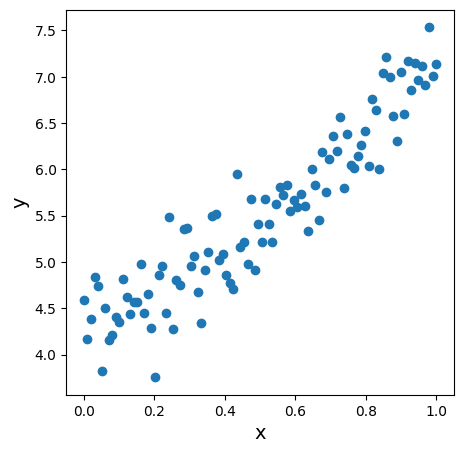

In [6]:
np.random.seed(0)
num_points = 100
X1 = np.linspace(0,1, num_points)
y1 = 4 + 3 * X1 + np.random.randn(num_points)/3

fig = plt.figure(figsize=(5, 5))
plt.scatter(X1, y1)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()

* Uma camada com um neurônio

O primeiro passo na geração de um modelo Keras é a definição da camada de entrada, de forma que o Keras conheças o formato de entrada já na construção. Isso é útil para a inicialização imediata dos pesos das camadas.  O argumento de entrada é uma tupla, na qual o primeiro elemento é o número de entradas da rede. O Keras acrescenta automaticamente uma dimensão inicial para representar o número de amostras processadas simultaneamente, o qual é o `bath_size`. No exemplo atual o número de amostras é 100 ,o número de entradas é 1, e a camada de entrada é definida como
```python  
Input(shape=(1,))
```
Assim, o tensor de entrada terá o formato (100,1). Com a  inclusão de uma camada com 1 neurônio e função de ativação linear completamos a definição do modelo. `model.compile`executa a compilação do modelo com os parâmetros informados, que são o otimizador (´optimizer´) usado pelo método dos gradientes descendentes, , a função de perdas (`loss`) responsável pelo monitoramento da convergência e a métrica (`metrics´) usada para avaliação do modelo durante o treinamento. 

In [7]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)
model1 = Sequential([
  Input(shape=(1,)),
  Dense(1, activation='linear'),
])
model1.compile(optimizer='adam', loss='mse', metrics=['mse'])
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

keras.fit é a biblioteca que executa o treino do modelo. Os argumentos transmitidos para a biblioteca são:

* X (dados de entrada): Os dados de entrada para o treinamento. Podem ser um array NumPy, um dataset do TensorFlow ou qualquer outro objeto válido semelhante a um tensor.
* y (dados-alvo): Os rótulos ou dados-alvo correspondentes aos dados de entrada X.
* `batch_size`: Número de amostras por atualização de gradiente. Define o tamanho de cada mini-lote (mini-batch) para o treinamento.
* `epochs`: O número de vezes que o processo deve iterar sobre todo o conjunto de dados. Isso define quantas vezes o modelo aprenderá a partir dos dados.
* `verbose`: Controla o nível de detalhamento (verbosity) do processo de treinamento:
* `validation_data`: Dados utilizados para avaliar o desempenho do modelo durante o treinamento; tipicamente, uma tupla (x_val, y_val).
* `validation_split`: Fração dos dados de treinamento a ser utilizada para validação (por exemplo, 0,2 significa que 20% dos dados serão usados ​​para validação).
* `callbacks`: Uma lista de funções de callback que são executadas em diferentes estágios do treinamento.
* `shuffle`: Define se os dados de treinamento devem ser embaralhados antes de cada época, visando melhorar a generalização.incluem os dados de treino  

In [8]:
history1 = model1.fit(X1, y1, epochs=1500, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 24.753681
Época 200: loss = 19.471712
Época 300: loss = 15.055065
Época 400: loss = 11.401672
Época 500: loss = 8.422864
Época 600: loss = 6.039799
Época 700: loss = 4.180168
Época 800: loss = 2.775459
Época 900: loss = 1.758618
Época 1000: loss = 1.062583
Época 1100: loss = 0.619989
Época 1200: loss = 0.364648
Época 1300: loss = 0.234972
Época 1400: loss = 0.178995
Época 1500: loss = 0.158869


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


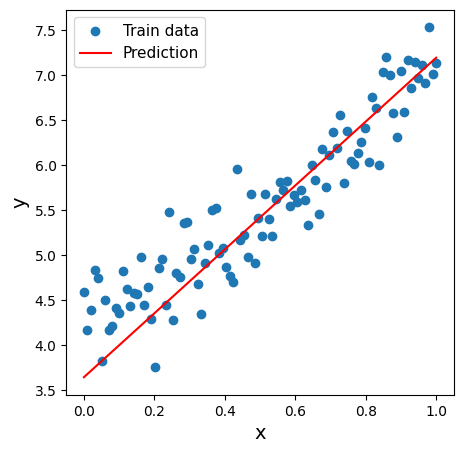

In [7]:
plot_test(X1,y1,model1)

* Rede com múltiplas camadas

In [9]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)
model2 = Sequential([
  Input(shape=(1,)),
  Dense(50, activation='linear'),
  Dense(1,activation='linear'),
])
model2.compile(optimizer='adam', loss='mse', metrics=['mse'])
model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                      │ (None, 50)                  │             100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              51 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
history2 = model2.fit(X1, y1, epochs=400, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.156789
Época 200: loss = 0.123737
Época 300: loss = 0.115460
Época 400: loss = 0.114693


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


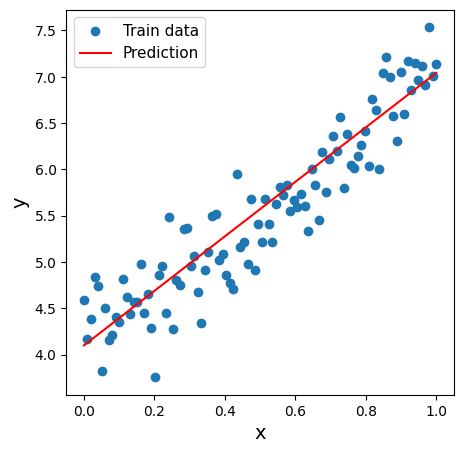

In [10]:
plot_test(X1,y1,model2)

#### **Regressão quadrática**

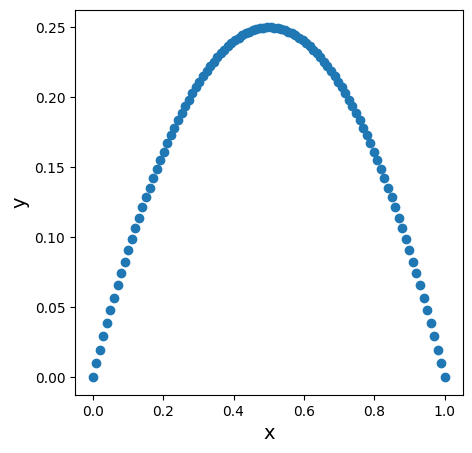

In [11]:
np.random.seed(0)
num_points = 100
X2 = np.linspace(0,1, num_points)
y2 = -(X2-0.5)**2 + 0.25

fig = plt.figure(figsize=(5, 5))
plt.scatter(X2, y2)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.show()


* Uma camada com um neurônio

In [12]:
np.random.seed(0)
random.seed(0)
tf.random.set_seed(0)

model3 = Sequential([
  Input(shape=(1,)),
  Dense(1, activation='relu'),
])
model3.compile(optimizer='adam', loss='mse', metrics=['mse'])
model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
history3 = model3.fit(X2, y2, epochs=1500, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.006314
Época 200: loss = 0.005878
Época 300: loss = 0.005827
Época 400: loss = 0.005821
Época 500: loss = 0.005820
Época 600: loss = 0.005820
Época 700: loss = 0.005820
Época 800: loss = 0.005820
Época 900: loss = 0.005820
Época 1000: loss = 0.005820
Época 1100: loss = 0.005820
Época 1200: loss = 0.005820
Época 1300: loss = 0.005820
Época 1400: loss = 0.005820
Época 1500: loss = 0.005820


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


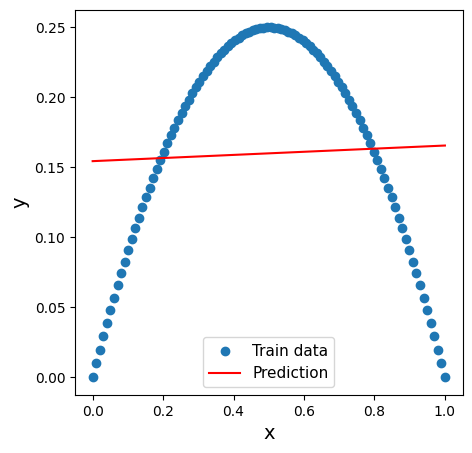

In [14]:
plot_test(X2,y2,model3)


* Rede com múltiplas camadas

In [15]:
np.random.seed(15)
random.seed(15)
tf.random.set_seed(15)

model4 = Sequential([
  Input(shape=(1,)),
  Dense(100, activation='relu'),
  Dense(1,activation='linear'),
])

model4.compile(optimizer='adam', loss='mse', metrics=['mse'])
model4.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 100)                 │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 301 (1.18 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
history4 = model4.fit(X2, y2, epochs=700, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.002114
Época 200: loss = 0.000750
Época 300: loss = 0.000283
Época 400: loss = 0.000110
Época 500: loss = 0.000047
Época 600: loss = 0.000023
Época 700: loss = 0.000012


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


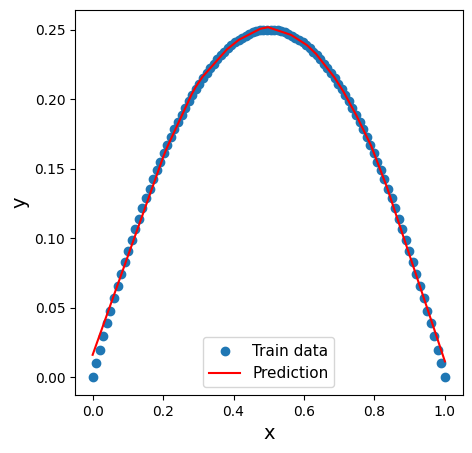

In [17]:
plot_test(X2,y2,model4)

**Observação:** Em uma segunda execução de model.fit() o **treinamento continuará a partir dos pesos obtidos no primeiro treinamento**. Os pesos não serão reinicializados. Além  disso, o otimizador Adam preserva informações da primeira execução como a média exponencial dos gradientes ou primeiros momentos, a média exponencial dos quadrados dos gradientes ou segundos momentos, e o contador de atualizações. Portanto, se for desejado reinicializar os pesos e os parâmetros do otimizador, o modelo pode ser recompilado antes de uma nova execução. 

In [18]:
history4 = model4.fit(X2, y2, epochs=700, verbose=0,
                      batch_size=32,callbacks=[PrintEvery100()])

Época 100: loss = 0.000007
Época 200: loss = 0.000004
Época 300: loss = 0.000003
Época 400: loss = 0.000002
Época 500: loss = 0.000001
Época 600: loss = 0.000001
Época 700: loss = 0.000001


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


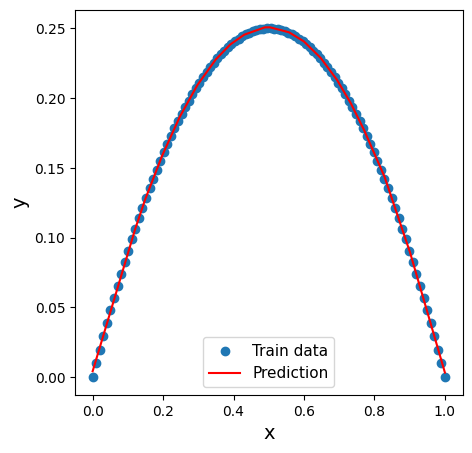

In [19]:
plot_test(X2,y2,model4)

#### **Classificação (Regressão Logística)**

In [20]:
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [21]:
# Normalize the images.
train_images = (X_train / 255) - 0.5
test_images = (X_test / 255) - 0.5

# Flatten the images.
train_images = train_images.reshape((-1, 784))
test_images = test_images.reshape((-1, 784))

In [22]:
model5 = Sequential([
  Input(shape=(784,)),
  Dense(64, activation='relu'),
  Dense(64, activation='relu'),
  Dense(10, activation='softmax'),
])
model5.compile(
  optimizer='adam',
  loss='categorical_crossentropy',
  metrics=['accuracy'],
)
model5.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
model5.fit(train_images,to_categorical(y_train),epochs=5,batch_size=32)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8240 - loss: 0.5688
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9376 - loss: 0.2054
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9540 - loss: 0.1511
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9626 - loss: 0.1216
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9689 - loss: 0.1046


In [24]:
model5.evaluate(
  test_images,
  to_categorical(y_test)
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9538 - loss: 0.1459


[0.12404832988977432, 0.9607999920845032]

In [25]:
predictions = model5.predict(test_images[:35])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


In [26]:
# Imprime a s predições.
print(np.argmax(predictions, axis=1)) 

# e compara com os rótulos reais.
print(y_test[:35]) # [7, 2, 1, 0, 4 ...]

[7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7]
[7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4 9 6 6 5 4 0 7 4 0 1 3 1 3 4 7]


#### **Previsão de consumo elétrico com a base de dados PJME_hourly**

A base PJME_hourly.csv contém  os dados de consumo de energia por hora e por dia da PJM Interconnection LLC (PJM), uma organização regional de transmissão (RTO) nos Estados Unidos que supervisiona o sistema de transmissão de energia elétrica na região leste. O conjunto de dados abrange o período de 2002 a 2018 e contém 145.336 registros horários e 6.057 registros diários. O conjunto de dados está disponível publicamente em

https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption?select=PJME_hourly.csv

##### **Importação de bibliotecas**

In [2]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense,Input
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

##### **Leitura e preparação dos dados**

* Inicialmente o pandas lê o arquivo CSV e cria um dataframe.
* O pandas converte a coluna *Datetime*, que inicialmente é composta por *strings* de texto, em objetos de data/hora que possam ser reconhecidos como valores reais. Por exemplo, '2002-01-01 01:00'é convertido em Timestamp('2002-01-01 01:00:00'). Isto é necessário porque séries temporais precisam de valores reais para todo tipo de processamento posterior.
* Estabelece a coluna *Datetime* como índice temporal da base de dados.
* O pandas reorganiza os dados para frequência horária (`resample('h')`), garantindo que a sequência de dados seja regular, com espaçamento temporal constante  e sem valores nulos. `mean()` agrega valores de múltiplos registros dentro da mesma horae substitui pela média. `ffill()` preenche os valores criados em `resample('h')` com os últimos valores válidos anteriores. Em séries temporais como esta os valores consecutivos costumam ser correlacionados, e manter o último valor quando uma nova amostra é criada preserva a continuidade temporal. 

In [7]:
df = pd.read_csv('Files\\PJME_hourly.csv')
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Agora os elementos da coluna Datetime são do tipo Timestamp
data = df['Datetime'].iloc[0]
print(data)
print('data:',data)
print('ano:',data.year)
print('mês:',data.month)
print('dia:',data.day)
print('hora:',data.hour)
print('type(data.hour:',type(data.hour))

data = df['Datetime'].iloc[1]
print('\n', data)
print('data:',data)
print('ano:',data.year)
print('mês:',data.month)
print('dia:',data.day)
print('hora:',data.hour)

df = df.set_index('Datetime')
df = df.resample('h').mean().ffill()  # Garantir frequência horária e sem valores nulos

2002-12-31 01:00:00
data: 2002-12-31 01:00:00
ano: 2002
mês: 12
dia: 31
hora: 1
type(data.hour: <class 'int'>

 2002-12-31 02:00:00
data: 2002-12-31 02:00:00
ano: 2002
mês: 12
dia: 31
hora: 2


##### **Visualização dos dados**

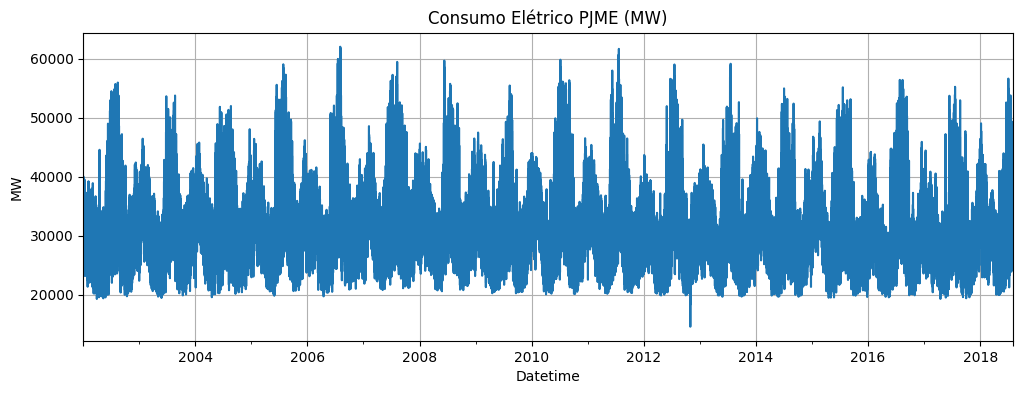

In [8]:
df.plot(figsize=(12, 4), title='Consumo Elétrico PJME (MW)', legend=False)
plt.ylabel("MW")
plt.grid(True)

plt.show()

##### **Pré-processamento dos dados para a RN**

* Valores muito grandes na base de dados podem causar explosão de gradientes, treinamento instável e saturação das funções de ativação sigmoide ou tanh. Por isso, `MinMaxScaler()` transforma os dados em um intervalo como `[0,1]`. Para isso ele aplica $x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}$.
* A rede não processa a série temporal inteira de uma vez, mas por sequências de tamanho fixo, onde ela aprende para cada sequência a prever os valores futuros. Neste caso são formadas sequências de 24 horas e previstas as próximas 6 horas.
* Após `create_sequences()`, cada elemento de X contém uma sequência de 24 hrs, e cada elemento de y contém as 6 horas futuras correspondentes ao mesmo elemento de X. Importante: `X[0,:]` conterá uma janela de 0 à 23hrs, e `y[0,:]` conterá as próximas 6 horas, ou seja, de 24 a 29 horas. Por sua vez, `X[1,:]` contém uma janela 1 a 24 horas, e `y[1,:]` contém de 25 a 30 horas. A cada intervalo a janela "escorrega" apenas uma hora.

In [9]:
# Normalização dos dados
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df).ravel() # scaled_data é um numpy.ndarray (N,)

# Função para criar janelas
def create_sequences(data, window_size=24, forecast_horizon=6):
    X, y = [], []
    for i in range(len(data) - window_size - forecast_horizon + 1):
        X.append(data[i:i+window_size]) # Cria o *array* de sequências de 24 horas
        y.append(data[i+window_size:i+window_size+forecast_horizon]) # o label(alvo) são as próximas 6 horas. 
    return np.array(X), np.array(y) # X e y são arrays NumPy. 

# Parâmetros
window_size = 24   # últimas 24 horas
forecast_horizon = 6  # prever as próximas 6 horas

X, y = create_sequences(scaled_data, window_size, forecast_horizon)

# Dividir em treino e teste
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

##### **Configuração do modelo**

In [13]:
keras.utils.set_random_seed(42)
model6 = keras.Sequential([
    keras.Input(shape=(24,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(6, activation='linear')
])
model6.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

model6.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 64)                  │           1,600 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 6)                   │             198 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,878 (15.15 KB)

 Trainable params: 3,878 (15.15 KB)

 Non-trainable params: 0 (0.00 B)

##### **Treino do modelo**

In [11]:
# Treinar modelo
history_false = model6.fit(X_train, y_train, epochs=150, batch_size=32, validation_split=0.1,shuffle=False)

Epoch 1/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - loss: 0.0058 - mae: 0.0476 - val_loss: 0.0015 - val_mae: 0.0297
Epoch 2/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 972us/step - loss: 0.0013 - mae: 0.0267 - val_loss: 0.0014 - val_mae: 0.0286
Epoch 3/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 996us/step - loss: 0.0011 - mae: 0.0244 - val_loss: 0.0014 - val_mae: 0.0287
Epoch 4/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 9.6636e-04 - mae: 0.0229 - val_loss: 0.0014 - val_mae: 0.0282
Epoch 5/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 8.8833e-04 - mae: 0.0220 - val_loss: 0.0014 - val_mae: 0.0276
Epoch 6/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 985us/step - loss: 8.4276e-04 - mae: 0.0214 - val_loss: 0.0013 - val_mae: 0.0265
Epoch 7/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 8.0596e-04 - mae: 0.0209 - val_loss: 0.0012 - val_mae: 0.0261
Epoch 8/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 7.8038e-04 - mae: 0.0205 - val_loss: 0.0012 - val_mae: 0.0256
Epoch 

##### **Verificação dos resultados**

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 545us/step
Horizonte 1h - RMSE: 379.72 MW
Horizonte 2h - RMSE: 593.10 MW
Horizonte 3h - RMSE: 809.24 MW
Horizonte 4h - RMSE: 1043.57 MW
Horizonte 5h - RMSE: 1273.41 MW
Horizonte 6h - RMSE: 1477.64 MW


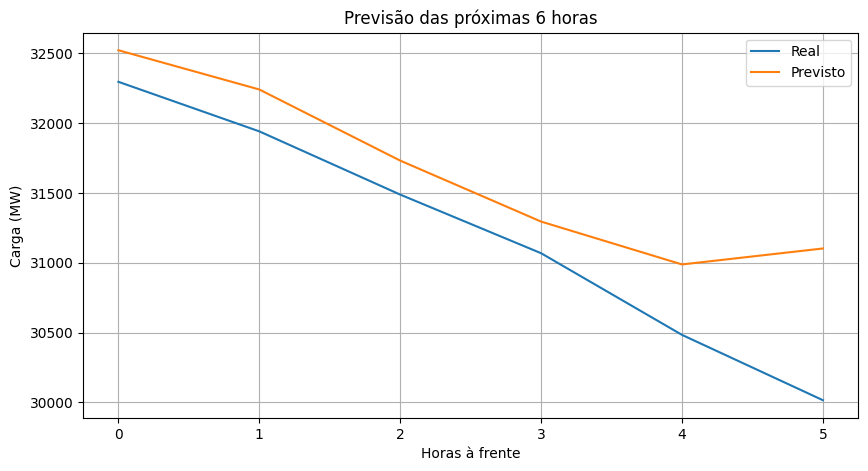

In [16]:
# Previsões
y_pred = model6.predict(X_test)

# Inverter normalização: Converte osdados de um tensor 3D para um tensor 2D de forma 
# que o inverse_tranformam() possa inverter a normalização e depois restaura o formato original dos dados. 
y_test_inv = scaler.inverse_transform(y_test)
y_pred_inv = scaler.inverse_transform(y_pred)

# Avaliação por horizonte
for h in range(forecast_horizon):
    rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], y_pred_inv[:, h]))#Erro qudrático médio
    mae = mean_absolute_error(y_test_inv[:, h], y_pred_inv[:, h])# Erro absoluto médio
    print(f'Horizonte {h+1}h - RMSE: {rmse:.2f} MW')

# Visualização para 1 exemplo
plt.figure(figsize=(10, 5))
plt.plot(range(6), y_test_inv[24], label='Real')
plt.plot(range(6), y_pred_inv[24], label='Previsto')
plt.xlabel('Horas à frente')
plt.ylabel('Carga (MW)')
plt.title('Previsão das próximas 6 horas')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Treinar modelo
keras.utils.set_random_seed(42)
history_true = model6.fit(X_train, y_train, epochs=150, batch_size=32, validation_split=0.1,shuffle=True)

Epoch 1/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - loss: 0.0058 - mae: 0.0432 - val_loss: 9.4312e-04 - val_mae: 0.0227
Epoch 2/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 991us/step - loss: 9.2270e-04 - mae: 0.0222 - val_loss: 8.0651e-04 - val_mae: 0.0206
Epoch 3/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 995us/step - loss: 8.0696e-04 - mae: 0.0206 - val_loss: 7.6438e-04 - val_mae: 0.0200
Epoch 4/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 990us/step - loss: 7.4732e-04 - mae: 0.0198 - val_loss: 7.3284e-04 - val_mae: 0.0195
Epoch 5/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 976us/step - loss: 7.0502e-04 - mae: 0.0191 - val_loss: 7.0292e-04 - val_mae: 0.0191
Epoch 6/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 6.7265e-04 - mae: 0.0186 - val_loss: 6.8560e-04 - val_mae: 0.0187
Epoch 7/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 991us/step - loss: 6.4910e-04 - mae: 0.0183 - val_loss: 6.6972e-04 - val_mae: 0.0185
Epoch 8/150
3271/3271 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 6.2946e-04 - mae: 0.0179 - v

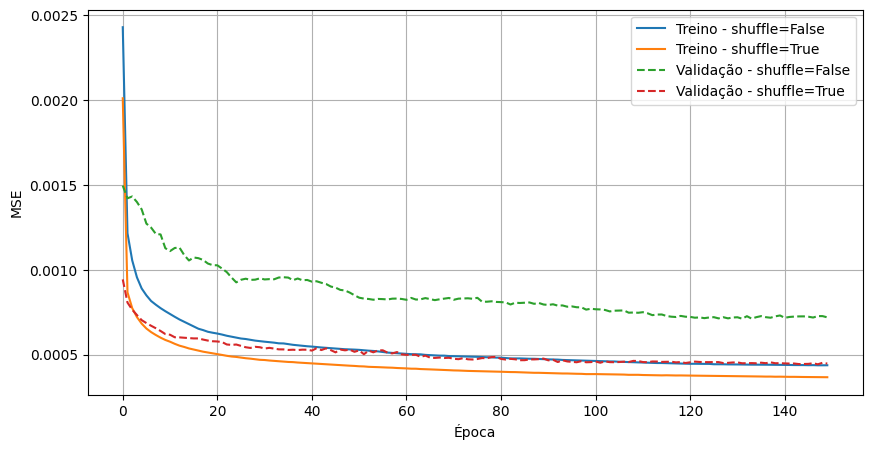

In [15]:
plt.figure(figsize=(10, 5))

plt.plot(history_false.history['loss'],
         label='Treino - shuffle=False')

plt.plot(history_true.history['loss'],
         label='Treino - shuffle=True')

plt.plot(history_false.history['val_loss'], '--',
         label='Validação - shuffle=False')

plt.plot(history_true.history['val_loss'], '--',
         label='Validação - shuffle=True')

plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

**Observações**

* A primeira hora apresenta um erro relativamente pequeno. O RMSE de aproximadamente 598 MW sugere que a rede conseguiu aprender relações entre as últimas 24 horas e a carga da hora seguinte.
* O erro aumenta progressivamente. Na sexta hora, o RMSE chega a aproximadamente 2.072 MW, cerca de 3,46 vezes o erro da primeira hora. Isso é compatível com o aumento da incerteza conforme nos afastamos da última observação.
*  Esse aumento não significa necessariamente acumulação de erros. Aqui está uma distinção conceitual importante: A rede densa possui seis neurônios de saída e produz as seis previsões simultaneamente. Portanto, a previsão da sexta hora não depende diretamente das cinco previsões anteriores.

In [23]:
def criar_modelo():
    model = keras.Sequential([
        keras.Input(shape=(24, 1)),
        keras.layers.Flatten(),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(6)
    ])

    model.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=0.01,
            momentum=0.0
        ),
        loss='mse'
    )

    return model

In [24]:
keras.utils.set_random_seed(0)
model_sem = criar_modelo()

history_sem = model_sem.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=0
)

keras.utils.set_random_seed(0)
model_com = criar_modelo()

history_com = model_com.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.1,
    shuffle=True,
    verbose=0
)

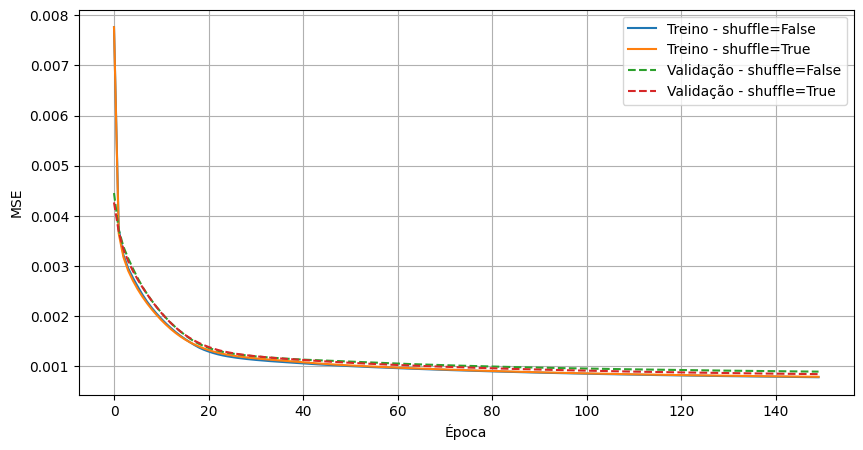

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(history_sem.history['loss'],
         label='Treino - shuffle=False')

plt.plot(history_com.history['loss'],
         label='Treino - shuffle=True')

plt.plot(history_sem.history['val_loss'], '--',
         label='Validação - shuffle=False')

plt.plot(history_com.history['val_loss'], '--',
         label='Validação - shuffle=True')

plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 560us/step
Horizonte 1h - RMSE: 651.25 MW
Horizonte 2h - RMSE: 961.68 MW
Horizonte 3h - RMSE: 1217.07 MW
Horizonte 4h - RMSE: 1466.30 MW
Horizonte 5h - RMSE: 1728.36 MW
Horizonte 6h - RMSE: 1896.05 MW


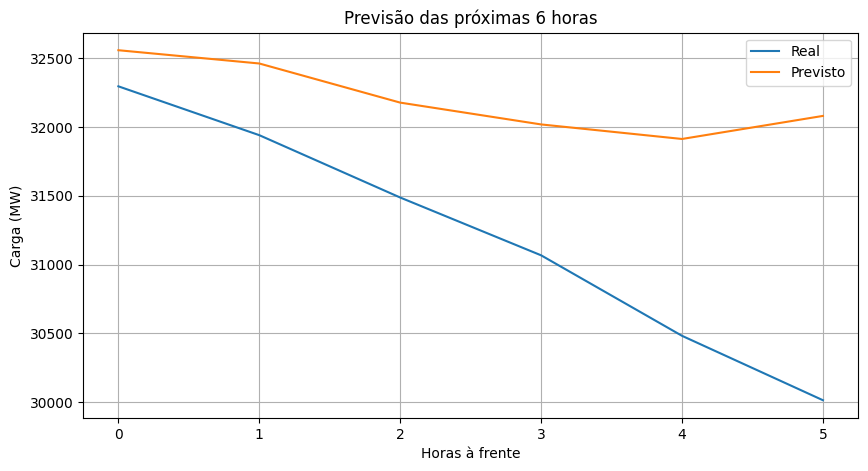

In [26]:
# Previsões
y_pred = model_sem.predict(X_test)

# Inverter normalização: Converte osdados de um tensor 3D para um tensor 2D de forma 
# que o inverse_tranformam() possa inverter a normalização e depois restaura o formato original dos dados. 
y_test_inv = scaler.inverse_transform(y_test)
y_pred_inv = scaler.inverse_transform(y_pred)

# Avaliação por horizonte
for h in range(forecast_horizon):
    rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], y_pred_inv[:, h]))#Erro qudrático médio
    mae = mean_absolute_error(y_test_inv[:, h], y_pred_inv[:, h])# Erro absoluto médio
    print(f'Horizonte {h+1}h - RMSE: {rmse:.2f} MW')

# Visualização para 1 exemplo
plt.figure(figsize=(10, 5))
plt.plot(range(6), y_test_inv[24], label='Real')
plt.plot(range(6), y_pred_inv[24], label='Previsto')
plt.xlabel('Horas à frente')
plt.ylabel('Carga (MW)')
plt.title('Previsão das próximas 6 horas')
plt.legend()
plt.grid(True)
plt.show()

909/909 ━━━━━━━━━━━━━━━━━━━━ 1s 561us/step
Horizonte 1h - RMSE: 574.40 MW
Horizonte 2h - RMSE: 872.60 MW
Horizonte 3h - RMSE: 1136.99 MW
Horizonte 4h - RMSE: 1387.94 MW
Horizonte 5h - RMSE: 1650.05 MW
Horizonte 6h - RMSE: 1829.55 MW


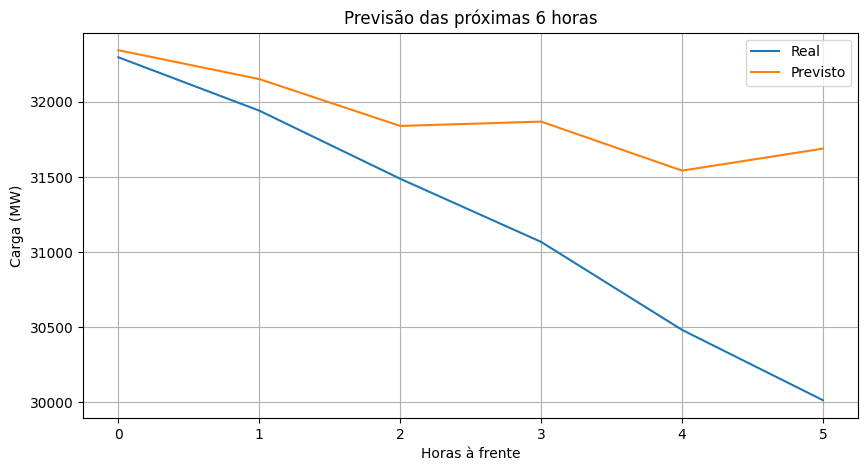

In [27]:
# Previsões
y_pred = model_com.predict(X_test)

# Inverter normalização: Converte osdados de um tensor 3D para um tensor 2D de forma 
# que o inverse_tranformam() possa inverter a normalização e depois restaura o formato original dos dados. 
y_test_inv = scaler.inverse_transform(y_test)
y_pred_inv = scaler.inverse_transform(y_pred)

# Avaliação por horizonte
for h in range(forecast_horizon):
    rmse = np.sqrt(mean_squared_error(y_test_inv[:, h], y_pred_inv[:, h]))#Erro qudrático médio
    mae = mean_absolute_error(y_test_inv[:, h], y_pred_inv[:, h])# Erro absoluto médio
    print(f'Horizonte {h+1}h - RMSE: {rmse:.2f} MW')

# Visualização para 1 exemplo
plt.figure(figsize=(10, 5))
plt.plot(range(6), y_test_inv[24], label='Real')
plt.plot(range(6), y_pred_inv[24], label='Previsto')
plt.xlabel('Horas à frente')
plt.ylabel('Carga (MW)')
plt.title('Previsão das próximas 6 horas')
plt.legend()
plt.grid(True)
plt.show()